# Efficient AI: a small, fast student that keeps the fusion model's accuracy

**Question (slide 14):** can we cut the computational cost substantially while keeping accuracy close to the
Member 2 multimodal model (`fusion_cnn`, seed 0, test R² 0.780)?

| Step | What | Where |
|---|---|---|
| Spectral reduction | Member 2 already tested PCA 122 → 16 bands: −0.013 R², and almost no FLOP saving (the 1×1 stem is 3 % of FLOPs). Here we also try dropping the 122 hyperspectral bands entirely. | `models/cnn.py` |
| Lightweight CNN | same two-branch fusion design, narrower (width 32/16 or 16/8 instead of 64/32), every 3×3 conv split into depthwise 3×3 + pointwise 1×1 | `efficient/lite.py` |
| Knowledge distillation | loss α·L_task + (1−α)·L_distill with MSE on outputs = training on the target α·y + (1−α)·teacher, α = 0.5 | `efficient/distill.py` |
| Input fix | NDVI / NDBI / MNDWI clipped to [−1, 1] (0.1 % of pixels had values up to 1452), normalised with clipped train statistics | `efficient/distill.Prepared` |
| Compression | ONNX export, INT8 dynamic quantisation (onnxruntime) | `efficient/benchmark.py` |

**Fair benchmark:** every model is scored on every valid pixel of the same 56 test cities with Member 2's
`evaluate_scenes`, trained with Member 2's schedule (60 epochs max, patience 10, 4000 patches per epoch), and timed on
the same machine (this laptop's CPU) with the same batch of 32 validation patches.

In [1]:
import json, time, warnings, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from torch.utils.data import DataLoader
from urbanheat.config import load_config
from urbanheat.data.dataset import PatchDataset
from urbanheat.efficient import benchmark, distill, lite
from urbanheat.models import baselines as B, train as T
warnings.filterwarnings("ignore")
cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90
torch.set_num_threads(4)

ds = {s: PatchDataset(H5, s) for s in ["val", "test"]}
prep = {s: distill.Prepared(d) for s, d in ds.items()}
with h5py.File(H5) as f:
    info_of = {k: dict(climate_group=g.attrs["climate_group"], sensor=g.attrs["sensor"]) for k, g in f["pairs"].items()}
import platform; print(platform.processor(), "|", torch.__version__, "| threads", torch.get_num_threads())

Intel64 Family 6 Model 142 Stepping 12, GenuineIntel | 2.15.0+cpu | threads 4


## Accuracy on the 56 test cities

In [2]:
TEACHERS = {"Member 2: fusion_cnn (teacher)": "cnn_robust_fusion_cnn_s0", "Member 2: fusion_pca_cnn": "cnn_robust_fusion_pca_cnn_s0",
            "Member 2: thermal_cnn": "cnn_robust_thermal_cnn_s0"}
STUDENTS = {p.name: p.name for p in sorted(RUNS.glob("m3_*")) if (p / "metrics.json").exists()}
MODELS = {**TEACHERS, **STUDENTS}
acc = {}
for label, run in MODELS.items():
    m = json.loads((RUNS / run / "metrics.json").read_text())
    acc[label] = dict(test_r2=m["test"]["r2"], test_mae=m["test"]["mae"], test_rmse=m["test"]["rmse"], val_r2=m["val"]["r2"],
                      alpha=m.get("alpha"), epochs=m.get("epochs_run"))
acc = pd.DataFrame(acc).T
acc.round(3)

,test_r2,test_mae,test_rmse,val_r2,alpha,epochs
Member 2: fusion_cnn (teacher),0.780,0.980,1.405,0.713,NaN,NaN
Member 2: fusion_pca_cnn,0.760,1.037,1.465,0.721,NaN,NaN
Member 2: thermal_cnn,0.741,1.034,1.521,0.670,NaN,NaN
m3_lite16_ce,0.777,0.984,1.411,0.718,1.0,48.0
m3_lite16_kd,0.784,0.981,1.391,0.728,0.5,60.0
m3_lite32_ce,0.761,1.041,1.463,0.726,1.0,57.0
m3_lite32_kd,0.784,0.976,1.390,0.729,0.5,49.0
m3_nohs32_kd,0.787,0.967,1.382,0.726,0.5,60.0


## Cost on this laptop: PyTorch, ONNX FP32 and ONNX INT8 (CPU)

In [3]:
batch = next(iter(DataLoader(prep["val"], batch_size=32)))     # same 32 validation patches for every model
raw_batch = next(iter(DataLoader(ds["val"], batch_size=32)))   # Member 2's models read the unclipped inputs
ONNX = RUNS / "m3_onnx"; ONNX.mkdir(exist_ok=True)
cost, models = {}, {}
for label, run in MODELS.items():
    m = lite.load(RUNS / run); models[label] = m
    b = raw_batch if run.startswith("cnn_") else batch
    r = benchmark.measure(m, b, "cpu", reps=10)
    fp32 = benchmark.export_onnx(m, b, ONNX / f"{run}.onnx")
    int8 = benchmark.quantize_int8(fp32, ONNX / f"{run}_int8.onnx")
    nb = {k: np.asarray(b[k]) for k in benchmark.INPUTS}
    cost[label] = dict(params=r["params"], mflops=r["flops"] / 1e6, size_mb=r["size_mb"], torch_ms=r["latency_ms"],
                       onnx_ms=benchmark.onnx_run(fp32, nb, 10)[0], int8_ms=benchmark.onnx_run(int8, nb, 10)[0],
                       int8_mb=round(int8.stat().st_size / 1e6, 3))
cost = pd.DataFrame(cost).T
cost.round(3)

,params,mflops,size_mb,torch_ms,onnx_ms,int8_ms,int8_mb
Member 2: fusion_cnn (teacher),293241.0,597.623,1.208,7.239,4.627,7.667,0.341
Member 2: fusion_pca_cnn,286457.0,583.729,1.189,7.167,4.740,7.716,0.342
Member 2: thermal_cnn,58489.0,118.686,0.251,2.013,0.952,2.116,0.086
m3_lite16_ce,7905.0,15.319,0.066,1.391,0.431,1.664,0.077
m3_lite16_kd,7905.0,15.319,0.066,1.275,0.456,1.622,0.077
m3_lite32_ce,18985.0,37.323,0.113,2.183,1.181,3.389,0.089
m3_lite32_kd,18985.0,37.323,0.113,2.177,1.159,3.300,0.089
m3_nohs32_kd,15081.0,29.327,0.097,2.312,0.654,3.136,0.085


## Does INT8 cost accuracy? (all 56 test cities, ONNX Runtime)

In [4]:
def onnx_scores(path, d):
    import onnxruntime as ort
    sess = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    names = [i.name for i in sess.get_inputs()]
    ys, ps = [], []
    for pid in d.pairs:
        s = d.scene(pid)
        p = sess.run(None, {k: np.asarray(s[k])[None] if k != "sensor" else np.array([s[k]]) for k in names})[0][0]
        ys.append(s["y"][s["mask"]]); ps.append(p[s["mask"]])
    return B.scores(np.concatenate(ys), np.concatenate(ps))

int8_acc = {}
for label, run in MODELS.items():
    d = ds["test"] if run.startswith("cnn_") else prep["test"]
    int8_acc[label] = dict(fp32_r2=acc.loc[label, "test_r2"], int8_r2=onnx_scores(ONNX / f"{run}_int8.onnx", d)["r2"])
int8_acc = pd.DataFrame(int8_acc).T
int8_acc["int8_loss"] = int8_acc.fp32_r2 - int8_acc.int8_r2
int8_acc.round(4)

,fp32_r2,int8_r2,int8_loss
Member 2: fusion_cnn (teacher),0.7796,0.7794,0.0002
Member 2: fusion_pca_cnn,0.7603,0.7542,0.0061
Member 2: thermal_cnn,0.7414,0.7414,-0.0000
m3_lite16_ce,0.7775,0.7769,0.0006
m3_lite16_kd,0.7839,0.7842,-0.0003
m3_lite32_ce,0.7608,0.7608,-0.0001
m3_lite32_kd,0.7841,0.7836,0.0005
m3_nohs32_kd,0.7866,0.7865,0.0002


## Accuracy vs cost

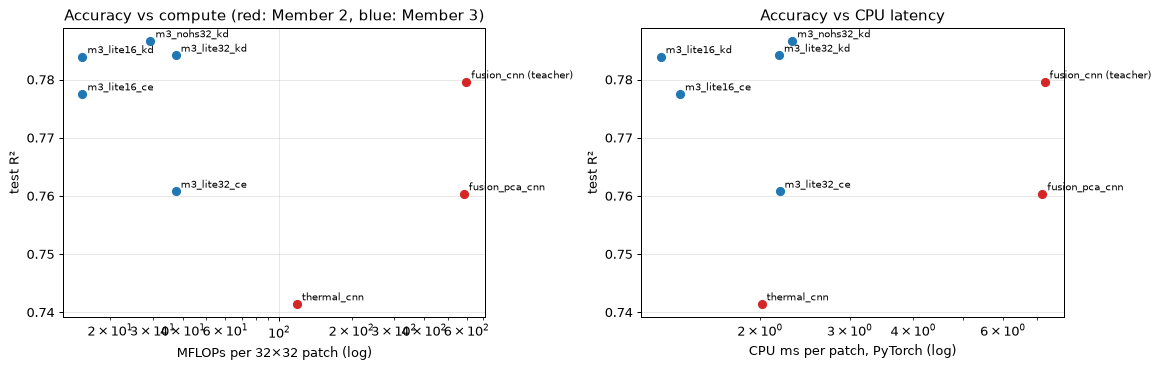

In [5]:
t = acc.join(cost)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, col, lab in [(ax[0], "mflops", "MFLOPs per 32×32 patch (log)"), (ax[1], "torch_ms", "CPU ms per patch, PyTorch (log)")]:
    for label, r in t.iterrows():
        c = "tab:red" if label.startswith("Member 2") else "tab:blue"
        a.scatter(r[col], r.test_r2, color=c, s=40, zorder=3)
        a.annotate(label.replace("Member 2: ", ""), (r[col], r.test_r2), fontsize=8, xytext=(4, 3), textcoords="offset points")
    a.set_xscale("log"); a.set_xlabel(lab); a.set_ylabel("test R²"); a.grid(alpha=.3)
ax[0].set_title("Accuracy vs compute (red: Member 2, blue: Member 3)"); ax[1].set_title("Accuracy vs CPU latency")
plt.tight_layout(); plt.show()

## Slide 17 table

In [6]:
teacher = "Member 2: fusion_cnn (teacher)"
s17 = pd.DataFrame({
    "MAE / RMSE / R²": [f"{r.test_mae:.2f} / {r.test_rmse:.2f} / {r.test_r2:.3f}" for _, r in t.iterrows()],
    "Params": [f"{int(p):,}" for p in t.params],
    "MFLOPs / patch": t.mflops.round(1),
    "Size (MB, FP32 / INT8)": [f"{a:.3f} / {b:.3f}" for a, b in zip(t.size_mb, t.int8_mb)],
    "CPU ms / patch (PyTorch / ONNX / INT8)": [f"{a:.2f} / {b:.2f} / {c:.2f}" for a, b, c in zip(t.torch_ms, t.onnx_ms, t.int8_ms)],
    "R² kept vs teacher": (t.test_r2 / t.loc[teacher, "test_r2"] * 100).round(1).astype(str) + " %",
    "FLOPs saved": ((1 - t.mflops / t.loc[teacher, "mflops"]) * 100).round(1).astype(str) + " %",
}, index=t.index)
s17.to_csv(RUNS / "m3_slide17.csv")
s17

,MAE / RMSE / R²,Params,MFLOPs / patch,"Size (MB, FP32 / INT8)",CPU ms / patch (PyTorch / ONNX / INT8),R² kept vs teacher,FLOPs saved
Member 2: fusion_cnn (teacher),0.98 / 1.40 / 0.780,"293,241",597.6,1.208 / 0.341,7.24 / 4.63 / 7.67,100.0 %,0.0 %
Member 2: fusion_pca_cnn,1.04 / 1.46 / 0.760,"286,457",583.7,1.189 / 0.342,7.17 / 4.74 / 7.72,97.5 %,2.3 %
Member 2: thermal_cnn,1.03 / 1.52 / 0.741,"58,489",118.7,0.251 / 0.086,2.01 / 0.95 / 2.12,95.1 %,80.1 %
m3_lite16_ce,0.98 / 1.41 / 0.777,"7,905",15.3,0.066 / 0.077,1.39 / 0.43 / 1.66,99.7 %,97.4 %
m3_lite16_kd,0.98 / 1.39 / 0.784,"7,905",15.3,0.066 / 0.077,1.27 / 0.46 / 1.62,100.6 %,97.4 %
m3_lite32_ce,1.04 / 1.46 / 0.761,"18,985",37.3,0.113 / 0.089,2.18 / 1.18 / 3.39,97.6 %,93.8 %
m3_lite32_kd,0.98 / 1.39 / 0.784,"18,985",37.3,0.113 / 0.089,2.18 / 1.16 / 3.30,100.6 %,93.8 %
m3_nohs32_kd,0.97 / 1.38 / 0.787,"15,081",29.3,0.097 / 0.085,2.31 / 0.65 / 3.14,100.9 %,95.1 %


## Summary

- **Best student: `m3_lite16_kd`**: test R² 0.784 (teacher 0.780), MAE 0.98 °C, **7,905 params (37× fewer), 15.3 MFLOPs per patch (97.4 % fewer)**, 0.07 MB, 0.46 ms per patch on a laptop CPU with ONNX (teacher 4.6 ms).
- `m3_nohs32_kd` (no hyperspectral input) is the most accurate at R² 0.787. So the hyperspectral branch adds compute, not accuracy, for this target.
- **Distillation matters**: at width 32, R² is 0.784 with the teacher and 0.761 without it (α = 1). At width 16 it is 0.784 vs 0.777.
- **NDVI/NDBI clipping** to [−1, 1] fixes the inflated normalisation (NDVI std 3.5 → 0.23). It also makes the student respond to greening (see 02).
- **INT8** (ONNX dynamic) shrinks the teacher 3.5× with no loss in R² (0.7796 → 0.7794). The students are already about 0.1 MB, so INT8 brings them nothing. INT8 is also slower than FP32 ONNX on this CPU.
